In [1]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\ Drive/Challenge2_nuova"
%cd $current_dir

Mounted at /gdrive
/gdrive/.shortcut-targets-by-id/1cd3Xbh9ZKbBedPV57qHiIKUqq2PyuVP_/Challenge2_nuova


In [2]:
# Set seed for reproducibility
SEED = 42

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
!pip install torchview
from torchview import draw_graph
from tqdm.notebook import tqdm

# Configurazione di TensorBoard e directory
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO


# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.9.0+cu126
Device: cuda


In [3]:
def load_images_from_folder(folder, num_images, file_prefix='img'):
    """
    Load and preprocess images from a specified folder in sequential order.
    Checks for existing .npy files first to speed up loading.

    Args:
        folder (str): Path to the folder containing images
        num_images (int): The total number of images to load, determining the max ID.
        file_prefix (str): Prefix for the image files (e.g., 'img', 'mask').

    Returns:
        np.ndarray: Array of preprocessed images with shape (N, H, W, C)
    """

    # Define the base .npy filename (e.g., 'train_data_img.npy')
    npy_filename = os.path.basename(os.path.normpath(folder)) + f'_{file_prefix}_560_new.npy'

    print(f"Loading {npy_filename} from disk...")
    # Attempt to load the .npy file from the constructed full path
    return np.load(npy_filename)



# Load images from the folder
train_path = 'an2dl2526c2/train/'
train_img = load_images_from_folder(train_path, num_images=692, file_prefix='img')

# Load images from the folder
test_path = 'an2dl2526c2/test/'
test_img = load_images_from_folder(test_path, num_images=477, file_prefix='img')

print(f"Loaded {len(train_img)} train images")
print(f"Loaded {len(test_img)} test images")

Loading train_img_560_new.npy from disk...
Loading test_img_560_new.npy from disk...
Loaded 691 train images
Loaded 477 test images


In [4]:
def load_masks_from_folder(folder, num_images, file_prefix='mask'):
    """
    Load and preprocess images from a specified folder in sequential order.
    Checks for existing .npy files first to speed up loading.

    Args:
        folder (str): Path to the folder containing images
        num_images (int): The total number of images to load, determining the max ID.
        file_prefix (str): Prefix for the mask files (e.g., 'mask').

    Returns:
        np.ndarray: Array of preprocessed images with shape (N, H, W, C)
    """
    # Define the .npy filename based on the folder name and prefix
    npy_filename = os.path.basename(os.path.normpath(folder)) + f'_{file_prefix}_560_new.npy'
    print(f"Loading {npy_filename} from disk...")
    return np.load(npy_filename)


# Load masks from the folder
train_path = 'an2dl2526c2/train/'
train_masks = load_masks_from_folder(train_path, num_images=691, file_prefix='masks')

# Load masks from the folder
test_path = 'an2dl2526c2/test/'
test_masks = load_masks_from_folder(test_path, num_images=477, file_prefix='masks')

print(f"Loaded {len(train_masks)} train masks")
print(f"Loaded {len(test_masks)} test masks")

Loading train_masks_560_new.npy from disk...
Loading test_masks_560_new.npy from disk...
Loaded 691 train masks
Loaded 477 test masks


In [5]:

# Number of images to display
num_img = 10

# Create subplots for displaying train images
fig, axes = plt.subplots(2, num_img//2, figsize=(20, 9))
for i in range(num_img):
    ax = axes[i%2, i%num_img//2]
    ax.imshow(np.clip(train_img[i], 0, 1))  # Display clipped train images
    ax.axis('off')
plt.tight_layout()
plt.show()

# Create subplots for displaying test images
fig, axes = plt.subplots(2, num_img//2, figsize=(20, 9))
for i in range(num_img):
    ax = axes[i%2, i%num_img//2]
    ax.imshow(np.clip(test_img[i], 0, 1))  # Display clipped test images
    ax.axis('off')
plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [6]:
import matplotlib.pyplot as plt
import numpy as np

def display_training_images_in_batches(images, start_id, total_images, images_per_batch=100):
    """
    Display training images in batches with their corresponding IDs.

    Args:
        images (np.ndarray): Array of training images.
        start_id (int): The starting ID for the first image in the dataset.
        total_images (int): The total number of images to display.
        images_per_batch (int): The number of images to display in each batch.
    """
    num_batches = (total_images + images_per_batch - 1) // images_per_batch

    for batch_idx in range(num_batches):
        current_start_idx = batch_idx * images_per_batch
        current_end_idx = min((batch_idx + 1) * images_per_batch, total_images)

        print(f"Displaying images from ID {current_start_idx} to {current_end_idx - 1}...")

        # Calculate grid dimensions dynamically
        num_images_in_current_batch = current_end_idx - current_start_idx
        if num_images_in_current_batch == 0:
            continue

        cols = 10 # Fixed number of columns for better layout
        rows = (num_images_in_current_batch + cols - 1) // cols

        fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2))
        axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

        for i in range(num_images_in_current_batch):
            image_index_in_dataset = current_start_idx + i
            ax = axes[i]
            ax.imshow(np.clip(images[image_index_in_dataset], 0, 1)) # Display clipped images
            ax.set_title(f"ID: {image_index_in_dataset}")
            ax.axis('off')

        # Turn off any unused subplots if num_images_in_current_batch is not a perfect multiple of cols
        for j in range(num_images_in_current_batch, len(axes)):
            axes[j].axis('off')

        plt.tight_layout()
        plt.show()

# Assuming train_img is already loaded and contains 691 images
# As per the previous cell output, train_img has 691 images (index 0 to 690)
num_total_train_images = len(train_img)
display_training_images_in_batches(train_img, 0, num_total_train_images, images_per_batch=100)


Output hidden; open in https://colab.research.google.com to view.

## 🔄 **Data Preprocessing**

In [ ]:
# Reduce 3-channel masks to 1 channel (e.g., by taking the first channel)
train_masks_1_channel = train_masks[:, :, :, 0:1]
test_masks_1_channel = test_masks[:, :, :, 0:1]

# Concatenate 'train_img' and 'train_masks_1_channel' along the channel axis to create 4-channel X_train
X_train = np.concatenate((train_img, train_masks_1_channel), axis=-1)
# Concatenate 'test_img' and 'test_masks_1_channel' along the channel axis to create 4-channel X_test
X_test = np.concatenate((test_img, test_masks_1_channel), axis=-1)

y_train = pd.read_csv("challenge_data/train_labels.csv")["label"];

In [ ]:
import numpy as np
import pandas as pd

indexes_to_eliminate = [1, 5, 8, 12, 18, 20, 22, 25, 27, 28, 36, 47, 48, 52,
                        62, 78, 85, 90, 94, 95, 126, 129, 130, 133, 136, 138,
                        148, 150, 155, 159, 161, 175, 178, 179, 180, 187, 189, 193, 196, 222, 237,
                        251, 253, 254, 263, 268, 270, 286, 293, 313, 319, 333, 342, 344, 346, 355,
                        368, 371, 376, 380, 390, 393, 407, 410, 415, 424, 440, 443, 453, 459, 463,
                        486, 497, 498, 499, 509, 521, 530, 531, 533, 537, 540, 544, 547, 557, 558,
                        560, 565, 567, 572, 576, 578, 580, 586, 602, 603, 607, 609, 614, 620, 623,
                        629, 635, 639, 643, 644, 645, 646, 656, 657, 658, 670, 673, 675]


# Create a boolean mask to identify the indices to keep
# This mask will be True for indices NOT in indexes_to_eliminate
all_indices = np.arange(len(X_train))
mask_to_keep = ~np.isin(all_indices, indexes_to_eliminate)

# Apply the mask to X_train and y_train
X_train = X_train[mask_to_keep]
y_train = y_train[mask_to_keep]

print(f"Shapes after eliminating indices: X_train.shape={X_train.shape}, y_train.shape={y_train.shape}")

# Note: The 'train_test_split' operation in a subsequent cell will now be applied
# to these filtered X_train and y_train. 'X_test' remains unchanged.

Shapes after eliminating indices: X_train.shape=(577, 560, 560, 4), y_train.shape=(577,)


In [ ]:
# Define a mapping of classes to integer labels
label_mapping = {
    'Luminal A': 0,
    'Luminal B': 1,
    'HER2(+)': 2,
    'Triple negative': 3,
}

y_train = y_train.map(label_mapping);

# Further split train_val into train and validation sets
X_train, X_val, y_train, y_val = train_test_split(
   X_train, y_train, random_state=SEED, test_size=0.15, stratify=y_train
)

# Print shapes of the datasets
print(f"Training Data Shape: {X_train.shape}")
print(f"Training Label Shape: {y_train.shape}")
print(f"Validation Data Shape: {X_val.shape}")
print(f"Validation Label Shape: {y_val.shape}")
print(f"Test Data Shape: {X_test.shape}")

Training Data Shape: (490, 560, 560, 4)
Training Label Shape: (490,)
Validation Data Shape: (87, 560, 560, 4)
Validation Label Shape: (87,)
Test Data Shape: (477, 560, 560, 4)


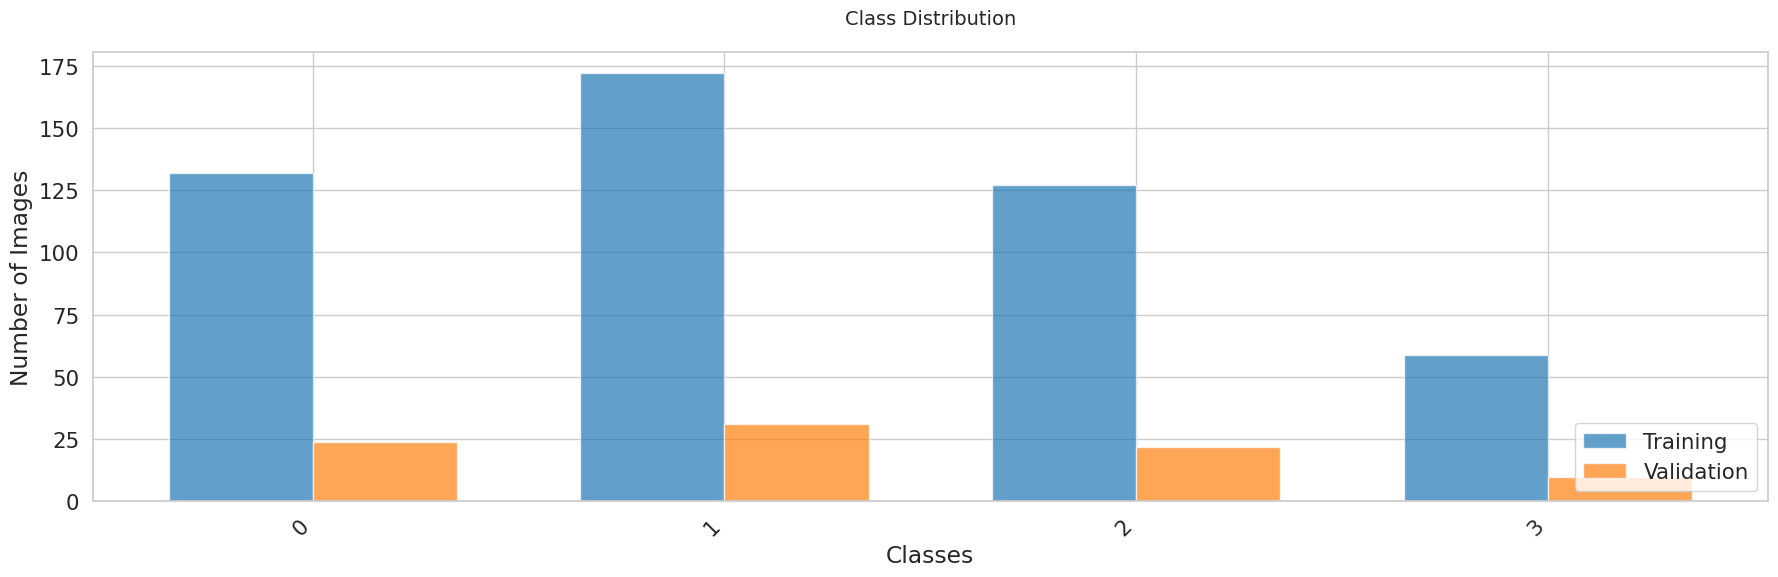

In [ ]:
def plot_class_distribution(y_train, y_val, class_names):
    """Plot class distribution for training and test sets."""
    sns.set_style("whitegrid")
    plt.figure(figsize=(18, 6))

    # Calculate class distributions for training and test sets
    train_dist = np.bincount(y_train)
    test_dist = np.bincount(y_val)

    # Create x positions and set bar width
    x = np.arange(len(class_names))
    width = 0.35

    # Plot bars for training and test distributions
    plt.bar(x - width / 2, train_dist, width, label='Training', color='#1f77b4', alpha=0.7)
    plt.bar(x + width / 2, test_dist, width, label='Validation', color='#ff7f0e', alpha=0.7)

    # Customize plot title and labels
    plt.title('Class Distribution', pad=20, fontsize=14)
    plt.xlabel('Classes')
    plt.ylabel('Number of Images')

    # Set class names as x-axis labels with rotation
    plt.xticks(x, class_names, rotation=45, ha='right')

    # Add legend for training and test distributions
    plt.legend(loc='lower right')

    # Adjust layout for optimal spacing
    plt.tight_layout()
    plt.show()

# Execute function to plot class distribution
plot_class_distribution(y_train, y_val, [0, 1, 2, 3])

##  📄 **Data Preprocessing**

In [ ]:
# Define the input shape and number of classes
input_shape = (4, 560, 560)
num_classes = 4

print("Input Shape:", input_shape)
print("Number of Classes:", num_classes)

Input Shape: (4, 560, 560)
Number of Classes: 4


In [ ]:
# Define the batch size
BATCH_SIZE = 64

In [ ]:
# ImageNet normalization statistics, extended for 4 channels. The 4th channel (mask) will not be altered.
IMAGENET_MEAN = [0.485, 0.456, 0.406, 0.0]
IMAGENET_STD = [0.229, 0.224, 0.225, 1.0]


class ChalDataset(torch.utils.data.Dataset):
    """Custom PyTorch Dataset for Oxford Pets with optional augmentation and normalization."""

    def __init__(self, data, labels, augmentation=None, normalize_imagenet=False):
        """
        Args:
            data: numpy array of images (N, C, H, W) in range [0, 1]
            labels: numpy array of labels
            augmentation: transforms for data augmentation
            normalize_imagenet: whether to apply ImageNet normalization
        """
        self.data = torch.from_numpy(data)
        self.labels = torch.from_numpy(labels).long()
        self.augmentation = augmentation
        self.normalize_imagenet = normalize_imagenet

        # ImageNet normalization transform
        if normalize_imagenet:
            self.normalize = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
        else:
            self.normalize = None

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx].clone()  # Image is (H, W, C) initially from numpy
        label = self.labels[idx]

        # Permute to (C, H, W) as PyTorch transforms expect this format
        image = image.permute(2, 0, 1) # Move channels to the first dimension

        # Apply augmentation if provided (on images in [0, 1] range)
        if self.augmentation:
            image = self.augmentation(image)

        # Apply ImageNet normalization if requested
        if self.normalize:
            image = self.normalize(image)

        return image, label

In [ ]:
def make_loader(ds, batch_size, shuffle, drop_last):
    """Create a PyTorch DataLoader with optimized settings."""
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,
    )

##  🧮 **Network Parameters**

In [ ]:
# Training parameters
LEARNING_RATE = 1e-3
EPOCHS = 200
PATIENCE = 20

# Regularization
DROPOUT_RATE = 0.3

# Smoothing constant for class weights
smoothing_constant = 50 # Adjust this value to control the level of smoothing

# Calculate class weights based on y_train distribution
class_counts = y_train.value_counts().sort_index()
total_samples = len(y_train)
# Apply smoothing by adding a constant to each class count
smoothed_class_counts = class_counts + smoothing_constant
class_weights = torch.tensor([total_samples / (len(class_counts) * count) for count in smoothed_class_counts], dtype=torch.float32).to(device)

# Set up loss function with class weights
criterion = nn.CrossEntropyLoss(weight=class_weights)
print(class_weights)
print(class_counts)

# Print the defined parameters
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Learning Rate:", LEARNING_RATE)
print("Dropout Rate:", DROPOUT_RATE)
print("Patience:", PATIENCE)
print("Class Weights:", class_weights.cpu().numpy())

tensor([0.6731, 0.5518, 0.6921, 1.1239], device='cuda:0')
label
0    132
1    172
2    127
3     59
Name: count, dtype: int64
Epochs: 200
Batch Size: 64
Learning Rate: 0.001
Dropout Rate: 0.3
Patience: 20
Class Weights: [0.6730769 0.5518018 0.6920904 1.1238532]


##  🧠 **Training Functions**

In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device):
    """Train for one epoch."""
    model.train()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad(set_to_none=True);

        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        # The explicit call to unscale_() is removed as scaler.step() handles it internally
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = accuracy_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions)
    )
    epoch_f1 = f1_score(np.concatenate(all_targets), np.concatenate(all_predictions), average='weighted')

    return epoch_loss, epoch_acc, epoch_f1


def validate_one_epoch(model, val_loader, criterion, device):
    """Validate for one epoch."""
    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = accuracy_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions)
    )
    epoch_f1 = f1_score(np.concatenate(all_targets), np.concatenate(all_predictions), average='weighted')

    return epoch_loss, epoch_accuracy, epoch_f1


def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=1, experiment_name=""):
    """Train the neural network model."""

    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': [],
        'train_f1': [], 'val_f1': []
    }

    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    for epoch in range(1, epochs + 1):
        train_loss, train_acc, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device
        )

        val_loss, val_acc, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_acc'].append(train_acc)
        training_history['val_acc'].append(val_acc)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        if writer is not None:
            writer.add_scalar('Loss/Training', train_loss, epoch)
            writer.add_scalar('Loss/Validation', val_loss, epoch)
            writer.add_scalar('Accuracy/Training', train_acc, epoch)
            writer.add_scalar('Accuracy/Validation', val_acc, epoch)
            writer.add_scalar('F1-Score/Training', train_f1, epoch)
            writer.add_scalar('F1-Score/Validation', val_f1, epoch)

        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, Acc={train_acc:.4f}, F1={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, Acc={val_acc:.4f}, F1={val_f1:.4f}")

        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("models/"+experiment_name+'_model.pt'))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    if patience == 0:
        torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')

    if writer is not None:
        writer.close()

    return model, training_history

In [ ]:
import torchvision.transforms.v2 as transforms

# Define augmentation for training
train_augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomApply([
        transforms.RandomAffine(degrees=(-30, 30), translate=(0.2, 0.2), scale=(0.8, 1.2))
    ], p=0.35),

])

# Create datasets WITHOUT ImageNet normalization (training from scratch)
train_scratch_ds = ChalDataset(X_train, y_train.values, augmentation=train_augmentation, normalize_imagenet=True)
val_scratch_ds = ChalDataset(X_val, y_val.values, augmentation=None, normalize_imagenet=True)

train_scratch_loader = make_loader(train_scratch_ds, BATCH_SIZE, shuffle=True, drop_last=False)
val_scratch_loader = make_loader(val_scratch_ds, BATCH_SIZE, shuffle=False, drop_last=False)

## 🛠️ **Transfer Learning**

In [ ]:
class EfficientNetB0TransferLearning(nn.Module):
    """EfficientNet-B0 with ImageNet pretrained weights."""

    def __init__(self, num_classes, dropout_rate=0.3, freeze_backbone=True):
        super().__init__()

        # Load weights pretrained on ImageNet
        self.backbone = torchvision.models.efficientnet_b0(
            weights=torchvision.models.EfficientNet_B0_Weights.DEFAULT
        )

        # Get the original first convolutional layer
        original_conv_stem = self.backbone.features[0][0]

        # Create a new convolutional layer with 4 input channels
        # Copy weights for the first 3 channels and initialize new channel weights to zero
        self.backbone.features[0][0] = nn.Conv2d(
            in_channels=4,  # New number of input channels
            out_channels=original_conv_stem.out_channels,
            kernel_size=original_conv_stem.kernel_size,
            stride=original_conv_stem.stride,
            padding=original_conv_stem.padding,
            bias=original_conv_stem.bias is not None,
        )

        # Copy weights from the original 3-channel layer to the new 4-channel layer
        with torch.no_grad():
            self.backbone.features[0][0].weight[:, :3, :, :].copy_(original_conv_stem.weight)
            # Initialize weights for the 4th channel to zero
            self.backbone.features[0][0].weight[:, 3:4, :, :].zero_()

        # Freeze the backbone layers (features)
        if freeze_backbone:
            for param in self.backbone.features.parameters():
                param.requires_grad = False

        # Replace classifier (Always trainable)
        in_features = self.backbone.classifier[-1].in_features
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(p=dropout_rate, inplace=True),
            nn.Linear(in_features, num_classes),
        )

    def forward(self, x):
        return self.backbone(x)

In [ ]:
class ResNet50TransferLearning(nn.Module):
    """ResNet50 with ImageNet pretrained weights."""

    def __init__(self, num_classes, dropout_rate=0.3, freeze_backbone=True):
        super().__init__()

        # Load weights pretrained on ImageNet
        self.backbone = torchvision.models.resnet50(
            weights=torchvision.models.ResNet50_Weights.DEFAULT
        )

        # Get the original first convolutional layer
        original_conv_stem = self.backbone.conv1

        # Create a new convolutional layer with 4 input channels
        # Copy weights for the first 3 channels and initialize new channel weights to zero
        self.backbone.conv1 = nn.Conv2d(
            in_channels=4,  # New number of input channels
            out_channels=original_conv_stem.out_channels,
            kernel_size=original_conv_stem.kernel_size,
            stride=original_conv_stem.stride,
            padding=original_conv_stem.padding,
            bias=original_conv_stem.bias is not None,
        )

        # Copy weights from the original 3-channel layer to the new 4-channel layer
        with torch.no_grad():
            self.backbone.conv1.weight[:, :3, :, :].copy_(original_conv_stem.weight)
            # Initialize weights for the 4th channel to zero
            self.backbone.conv1.weight[:, 3:4, :, :].zero_()

        # Freeze the backbone layers (features)
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False

        # Replace classifier (Always trainable)
        in_features = self.backbone.fc.in_features
        classifier_layers = []
        if dropout_rate > 0:
            classifier_layers.append(nn.Dropout(p=dropout_rate, inplace=True))
        classifier_layers.append(nn.Linear(in_features, num_classes))
        self.backbone.fc = nn.Sequential(*classifier_layers)

    def forward(self, x):
        return self.backbone(x)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 104MB/s]


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 280, 280]           1,152
       BatchNorm2d-2         [-1, 32, 280, 280]              64
              SiLU-3         [-1, 32, 280, 280]               0
            Conv2d-4         [-1, 32, 280, 280]             288
       BatchNorm2d-5         [-1, 32, 280, 280]              64
              SiLU-6         [-1, 32, 280, 280]               0
 AdaptiveAvgPool2d-7             [-1, 32, 1, 1]               0
            Conv2d-8              [-1, 8, 1, 1]             264
              SiLU-9              [-1, 8, 1, 1]               0
           Conv2d-10             [-1, 32, 1, 1]             288
          Sigmoid-11             [-1, 32, 1, 1]               0
SqueezeExcitation-12         [-1, 32, 280, 280]               0
           Conv2d-13         [-1, 16, 280, 280]             512
      BatchNorm2d-14         [-1, 16, 2

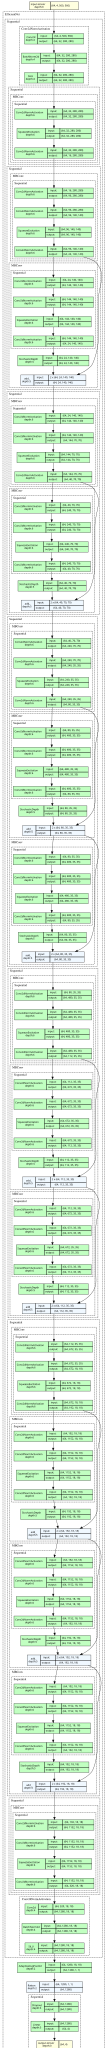

In [ ]:
# Create transfer learning model
tl_model = EfficientNetB0TransferLearning(num_classes, DROPOUT_RATE, freeze_backbone=True).to(device)

# Display model summary
summary(tl_model, input_size=input_shape)
model_graph = draw_graph(tl_model, input_size=(BATCH_SIZE,)+input_shape, expand_nested=True, depth=6)
model_graph.visual_graph

In [ ]:
# Create datasets WITH ImageNet normalization (for pretrained model)
train_tl_ds = ChalDataset(X_train, y_train.values, augmentation=train_augmentation, normalize_imagenet=True)
val_tl_ds = ChalDataset(X_val, y_val.values, augmentation=None, normalize_imagenet=True)

train_tl_loader = make_loader(train_tl_ds, BATCH_SIZE, shuffle=True, drop_last=False)
val_tl_loader = make_loader(val_tl_ds, BATCH_SIZE, shuffle=False, drop_last=False)

In [ ]:
# Setup training

experiment_name = "DARIOPENNONE"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
optimizer = torch.optim.Adam(tl_model.parameters(), lr=LEARNING_RATE)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [ ]:
%%time
# Train with transfer learning
tl_model, tl_history = fit(
    model=tl_model,
    train_loader=train_tl_loader,
    val_loader=val_tl_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=5,
    experiment_name=experiment_name,
    patience=PATIENCE
)

final_val_f1 = round(max(tl_history['val_f1']) * 100, 2)
print(f'Final validation f1: {final_val_f1}%')

Training 200 epochs...
Epoch   1/200 | Train: Loss=1.3858, Acc=0.2898, F1=0.2875 | Val: Loss=1.4153, Acc=0.2759, F1=0.2397
Epoch   5/200 | Train: Loss=1.2926, Acc=0.4286, F1=0.4214 | Val: Loss=1.4194, Acc=0.2184, F1=0.2201
Epoch  10/200 | Train: Loss=1.2427, Acc=0.4449, F1=0.4468 | Val: Loss=1.4426, Acc=0.2529, F1=0.2517
Epoch  15/200 | Train: Loss=1.2121, Acc=0.4837, F1=0.4821 | Val: Loss=1.4800, Acc=0.3103, F1=0.3093
Epoch  20/200 | Train: Loss=1.1912, Acc=0.4837, F1=0.4820 | Val: Loss=1.4994, Acc=0.2989, F1=0.2970
Epoch  25/200 | Train: Loss=1.1633, Acc=0.4816, F1=0.4824 | Val: Loss=1.5090, Acc=0.2874, F1=0.2896
Epoch  30/200 | Train: Loss=1.1713, Acc=0.4776, F1=0.4767 | Val: Loss=1.5215, Acc=0.2874, F1=0.2923
Epoch  35/200 | Train: Loss=1.1293, Acc=0.5286, F1=0.5297 | Val: Loss=1.5136, Acc=0.2989, F1=0.3029
Early stopping triggered after 37 epochs.
Best model restored from epoch 17 with val_f1 0.3179
Final validation f1: 31.79%
CPU times: user 2min 46s, sys: 33.9 s, total: 3min 20s

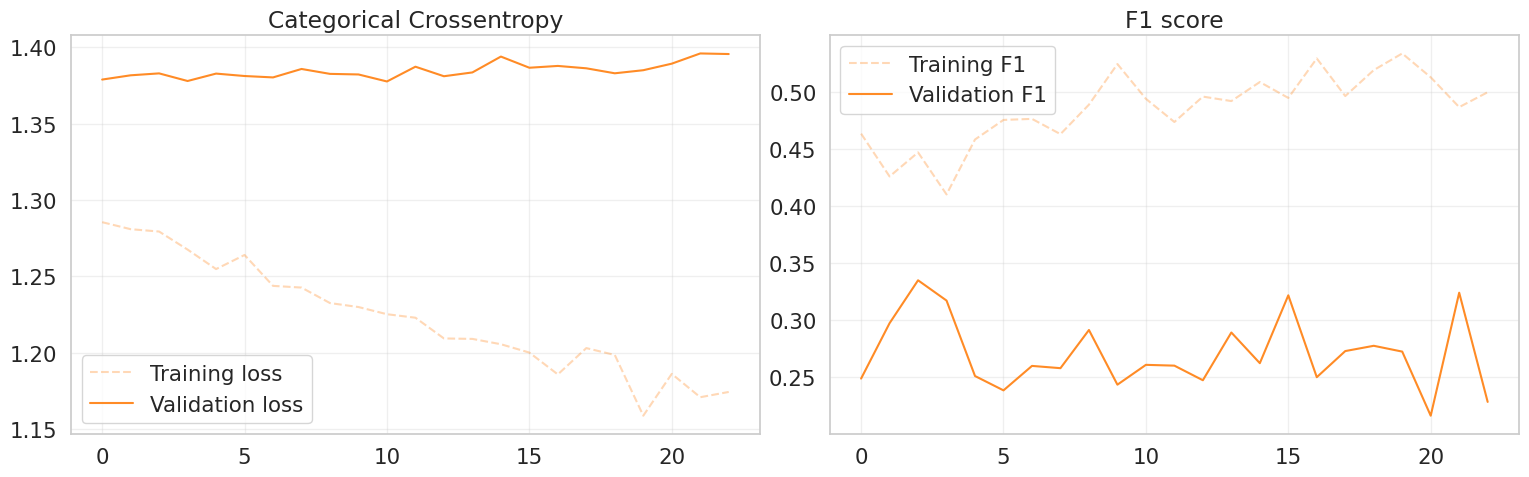

In [ ]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(tl_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(tl_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(tl_history['train_f1'], label='Training F1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(tl_history['val_f1'], label='Validation F1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

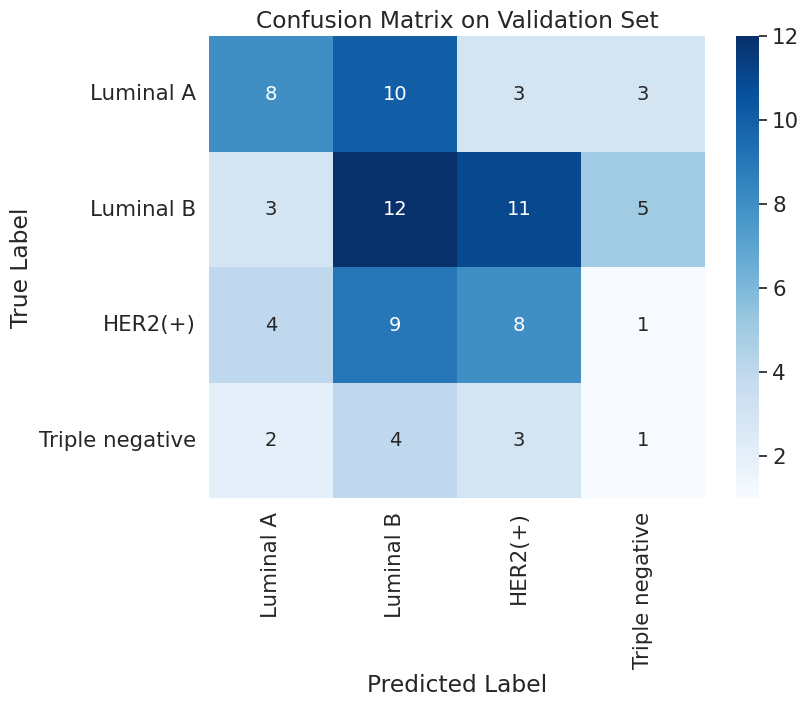

In [ ]:
inverse_label_mapping = {v: k for k, v in label_mapping.items()}
def plot_confusion_matrix(y_true, y_pred, classes):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title('Confusion Matrix on Validation Set')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

# Make predictions on the validation set using the fine-tuned model
tl_model.eval()
val_predictions = []
val_true_labels = []

with torch.no_grad():
    for inputs, targets in val_tl_loader:
        inputs = inputs.to(device)
        outputs = tl_model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        val_predictions.extend(predicted.cpu().numpy())
        val_true_labels.extend(targets.cpu().numpy())

# Get class names from inverse label mapping
class_names = [inverse_label_mapping[i] for i in sorted(inverse_label_mapping.keys())]

# Plot the confusion matrix
plot_confusion_matrix(val_true_labels, val_predictions, class_names)

## 🛠️ **Fine-Tuning**

In [ ]:
# Load the transfer learning model
ft_model = EfficientNetB0TransferLearning(num_classes, DROPOUT_RATE, freeze_backbone=False).to(device)
ft_model.load_state_dict(torch.load("models/porfavor2_model.pt"))

# Unfreeze the last N layers of the backbone
N_LAYERS_TO_UNFREEZE = 20

# Strategy: Freeze everything first, then unfreeze the last few blocks
for param in ft_model.parameters():
    param.requires_grad = False

# The classifier is always trainable
for param in ft_model.backbone.classifier.parameters():
    param.requires_grad = True

# Unfreeze the last 2 blocks of the feature extractor (EfficientNet-B0 has 9 blocks usually)
# Adjust slice index [-2:] to unfreeze more or fewer layers
for block in ft_model.backbone.features[-2:]:
    for param in block.parameters():
        param.requires_grad = True

# Check trainable parameters
trainable_params = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in ft_model.parameters())
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")

Trainable parameters: 1,134,516 / 4,012,960


In [ ]:
# Reuse datasets from transfer learning (with ImageNet normalization)
train_ft_ds = ChalDataset(X_train, y_train.values, augmentation=train_augmentation, normalize_imagenet=True)
val_ft_ds = ChalDataset(X_val, y_val.values, augmentation=None, normalize_imagenet=True)

train_ft_loader = make_loader(train_ft_ds, BATCH_SIZE, shuffle=True, drop_last=False)
val_ft_loader = make_loader(val_ft_ds, BATCH_SIZE, shuffle=False, drop_last=False)

In [ ]:
# Setup Training (Lower learning rate for Fine-Tuning)
experiment_name = "fine_tuning_porfavor"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
optimizer = torch.optim.Adam(ft_model.parameters(), lr=1e-5) # 10x smaller LR optimizer = torch.optim.Adam(ft_model.parameters(), lr=1e-5)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [ ]:
%%time
# Fine-tune the model
ft_model, ft_history = fit(
    model=ft_model,
    train_loader=train_ft_loader,
    val_loader=val_ft_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=5,
    experiment_name=experiment_name,
    patience=PATIENCE
)

final_val_f1 = round(max(ft_history['val_f1']) * 100, 2)
print(f'Final validation F1: {final_val_f1}%')

Training 200 epochs...
Epoch   1/200 | Train: Loss=1.2134, Acc=0.5082, F1=0.5090 | Val: Loss=1.4617, Acc=0.3563, F1=0.3544
Epoch   5/200 | Train: Loss=1.2163, Acc=0.4939, F1=0.4947 | Val: Loss=1.4607, Acc=0.3563, F1=0.3604
Epoch  10/200 | Train: Loss=1.2209, Acc=0.4469, F1=0.4491 | Val: Loss=1.4654, Acc=0.3563, F1=0.3617
Epoch  15/200 | Train: Loss=1.2222, Acc=0.4531, F1=0.4540 | Val: Loss=1.4695, Acc=0.3448, F1=0.3461
Epoch  20/200 | Train: Loss=1.1998, Acc=0.4755, F1=0.4756 | Val: Loss=1.4640, Acc=0.3563, F1=0.3608
Early stopping triggered after 24 epochs.
Best model restored from epoch 4 with val_f1 0.3802
Final validation F1: 38.02%
CPU times: user 1min 41s, sys: 25.4 s, total: 2min 6s
Wall time: 2min 44s


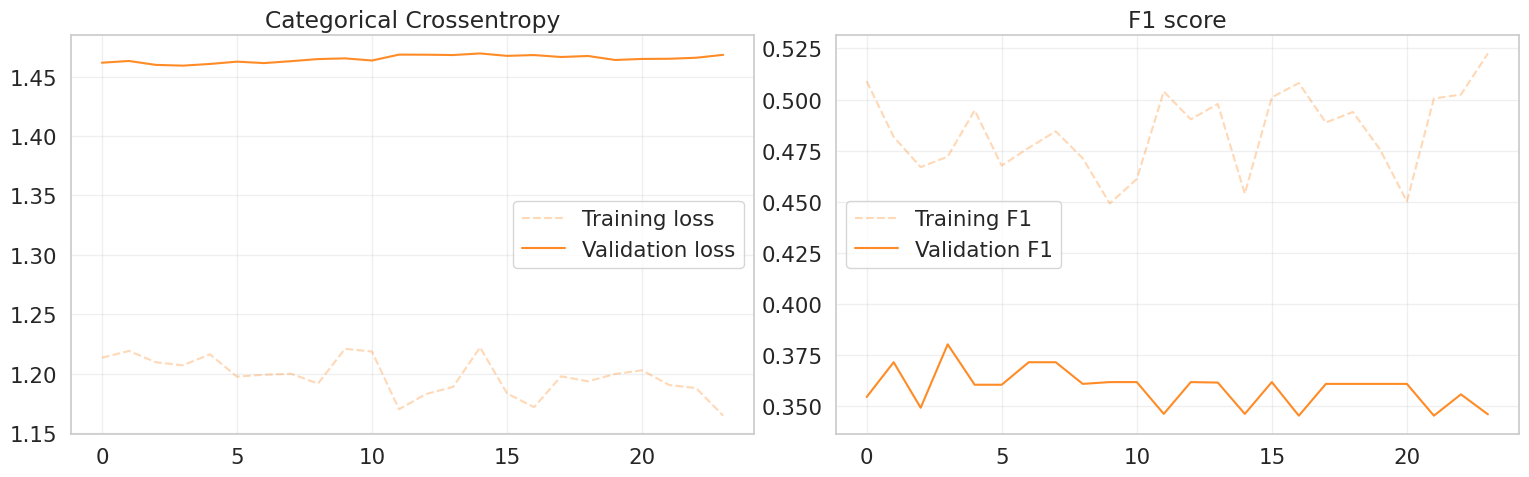

In [ ]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(ft_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(ft_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(ft_history['train_f1'], label='Training F1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(ft_history['val_f1'], label='Validation F1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

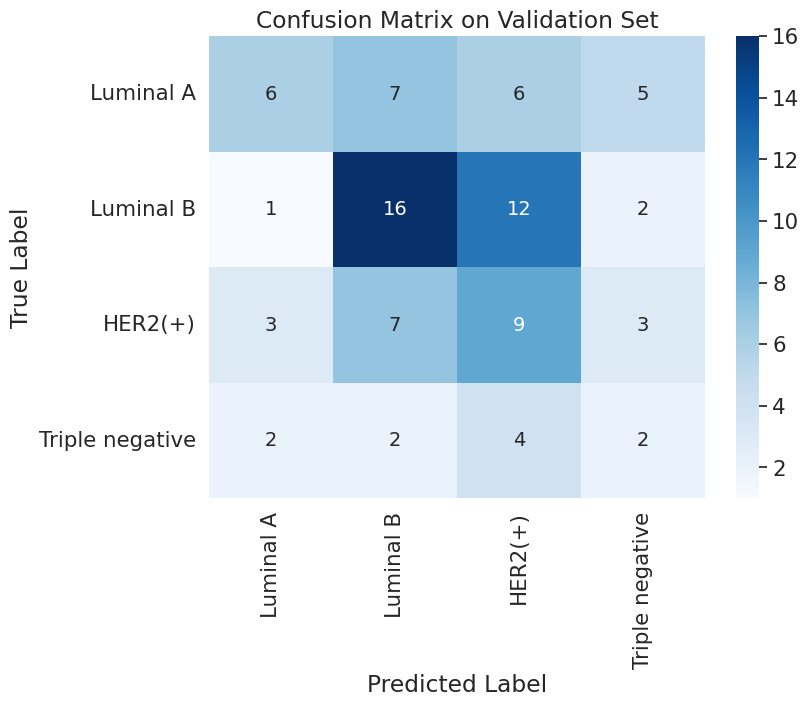

In [ ]:
def plot_confusion_matrix(y_true, y_pred, classes):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title('Confusion Matrix on Validation Set')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

# Make predictions on the validation set using the fine-tuned model
ft_model.eval()
val_predictions = []
val_true_labels = []

with torch.no_grad():
    for inputs, targets in val_ft_loader:
        inputs = inputs.to(device)
        outputs = ft_model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        val_predictions.extend(predicted.cpu().numpy())
        val_true_labels.extend(targets.cpu().numpy())

# Get class names from inverse label mapping
class_names = [inverse_label_mapping[i] for i in sorted(inverse_label_mapping.keys())]

# Plot the confusion matrix
plot_confusion_matrix(val_true_labels, val_predictions, class_names)

## 🛠️ **Fine-Tuning v2**

In [ ]:
# Load the transfer learning model
ft_model = EfficientNetB0TransferLearning(num_classes, DROPOUT_RATE, freeze_backbone=False).to(device)
ft_model.load_state_dict(torch.load("models/fine_tuning_porfavor_model.pt"))

# Unfreeze the last N layers of the backbone
N_LAYERS_TO_UNFREEZE = 20

# Strategy: Freeze everything first, then unfreeze the last few blocks
for param in ft_model.parameters():
    param.requires_grad = False

# The classifier is always trainable
for param in ft_model.backbone.classifier.parameters():
    param.requires_grad = True

# Unfreeze the last 2 blocks of the feature extractor (EfficientNet-B0 has 9 blocks usually)
# Adjust slice index [-2:] to unfreeze more or fewer layers
for block in ft_model.backbone.features[-3:-2]:
    for param in block.parameters():
        param.requires_grad = True

# Check trainable parameters
trainable_params = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in ft_model.parameters())
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")

Trainable parameters: 2,031,472 / 4,012,960


In [ ]:
# Reuse datasets from transfer learning (with ImageNet normalization)
train_ft_ds = ChalDataset(X_train, y_train.values, augmentation=train_augmentation, normalize_imagenet=True)
val_ft_ds = ChalDataset(X_val, y_val.values, augmentation=None, normalize_imagenet=True)

train_ft_loader = make_loader(train_ft_ds, BATCH_SIZE, shuffle=True, drop_last=False)
val_ft_loader = make_loader(val_ft_ds, BATCH_SIZE, shuffle=False, drop_last=False)

In [ ]:
# Setup Training (Lower learning rate for Fine-Tuning)
experiment_name = "fine_tuning_porfavor_2"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, ft_model.parameters()), lr=1e-6)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [ ]:
%%time
# Fine-tune the model
ft_model, ft_history = fit(
    model=ft_model,
    train_loader=train_ft_loader,
    val_loader=val_ft_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=5,
    experiment_name=experiment_name,
    patience=PATIENCE
)

final_val_f1 = round(max(ft_history['val_f1']) * 100, 2)
print(f'Final validation F1: {final_val_f1}%')

Training 200 epochs...
Epoch   1/200 | Train: Loss=1.2088, Acc=0.4980, F1=0.4983 | Val: Loss=1.4621, Acc=0.3793, F1=0.3805
Epoch   5/200 | Train: Loss=1.2031, Acc=0.4857, F1=0.4865 | Val: Loss=1.4608, Acc=0.3793, F1=0.3789
Epoch  10/200 | Train: Loss=1.1938, Acc=0.4653, F1=0.4650 | Val: Loss=1.4635, Acc=0.3563, F1=0.3617
Epoch  15/200 | Train: Loss=1.2165, Acc=0.4755, F1=0.4758 | Val: Loss=1.4612, Acc=0.3448, F1=0.3472
Epoch  20/200 | Train: Loss=1.2074, Acc=0.4449, F1=0.4448 | Val: Loss=1.4647, Acc=0.3563, F1=0.3617
Early stopping triggered after 21 epochs.
Best model restored from epoch 1 with val_f1 0.3805
Final validation F1: 38.05%
CPU times: user 1min 45s, sys: 25.5 s, total: 2min 11s
Wall time: 2min 44s


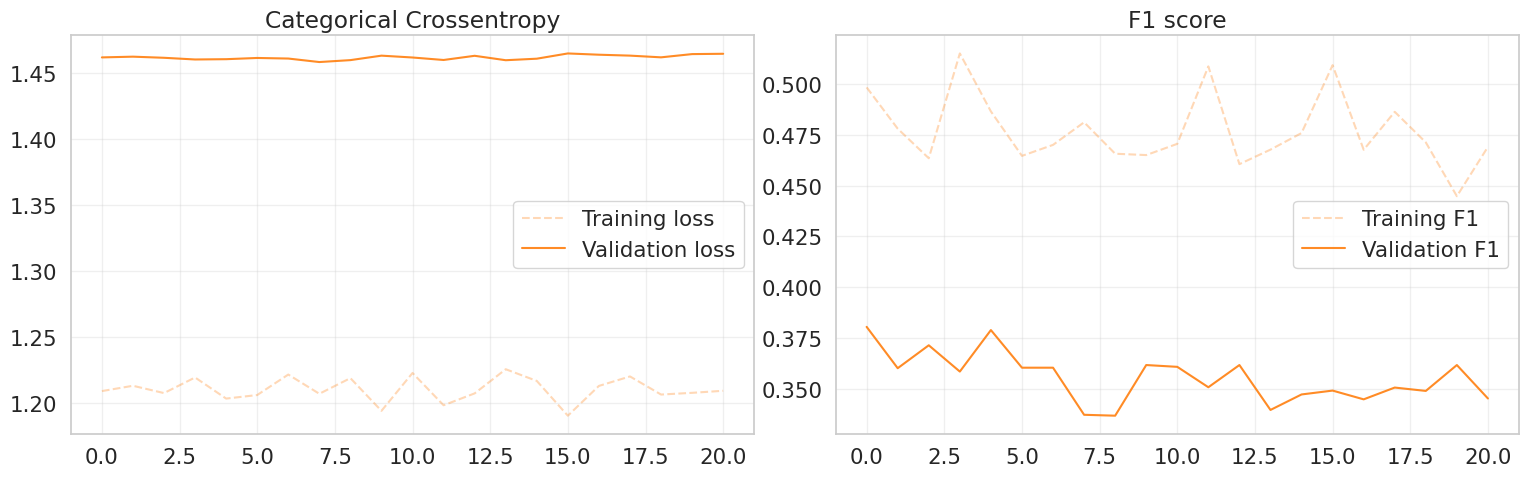

In [ ]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(ft_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(ft_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(ft_history['train_f1'], label='Training F1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(ft_history['val_f1'], label='Validation F1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

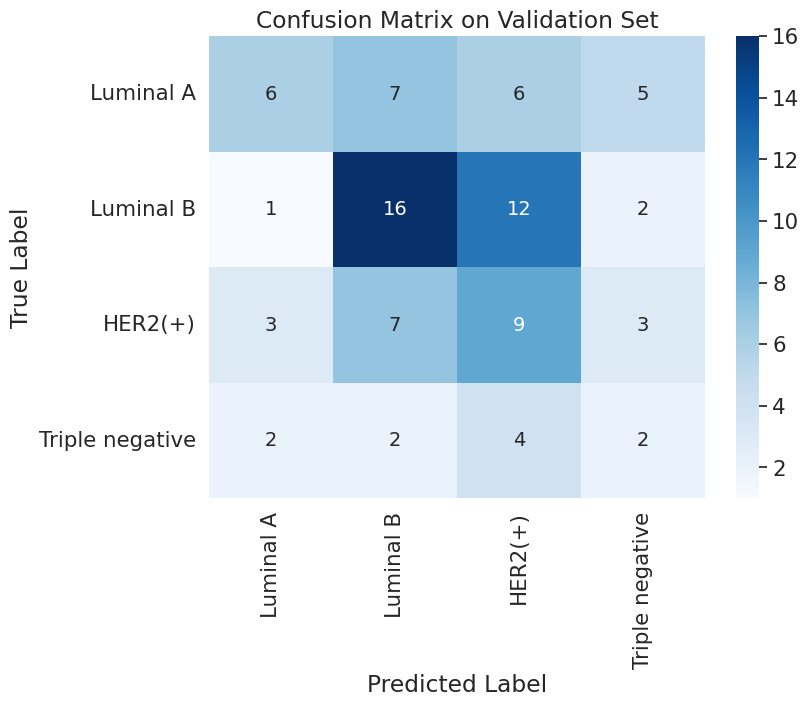

In [ ]:
def plot_confusion_matrix(y_true, y_pred, classes):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title('Confusion Matrix on Validation Set')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

# Make predictions on the validation set using the fine-tuned model
ft_model.eval()
val_predictions = []
val_true_labels = []

with torch.no_grad():
    for inputs, targets in val_ft_loader:
        inputs = inputs.to(device)
        outputs = ft_model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        val_predictions.extend(predicted.cpu().numpy())
        val_true_labels.extend(targets.cpu().numpy())

# Get class names from inverse label mapping
class_names = [inverse_label_mapping[i] for i in sorted(inverse_label_mapping.keys())]

# Plot the confusion matrix
plot_confusion_matrix(val_true_labels, val_predictions, class_names)

## **🔄 Test Time Augmentation (TTA)**

In [ ]:
# Custom Dataset class that applies transforms v2 on-the-fly
class AugmentedDataset(torch.utils.data.Dataset):
    """
    Custom PyTorch Dataset that applies data augmentation transforms using transforms v2.

    Following the recommended approach from torchvision documentation:
    - Use ToImage() to convert PIL to tensor
    - Use ToDtype(torch.float32, scale=True) to convert to float and scale to [0, 1]

    Args:
        data (np.ndarray): Input images with shape (N, H, W, C)
        labels (np.ndarray): Labels with shape (N,)
        transform (callable, optional): Transform to apply to images
    """
    def __init__(self, data, labels, transform=None):
        self.data = data
        self.labels = labels
        self.transform = transform

        # Base transform: convert to tensor (following v2 guidelines)
        self.to_tensor = transforms.Compose([
            transforms.ToImage(),
            transforms.ToDtype(torch.float32, scale=True)
        ])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        # Get image and label
        image = self.data[idx]
        label = self.labels[idx]

        # Convert numpy to PIL Image
        image_pil = Image.fromarray((image * 255).astype(np.uint8))

        # Convert to tensor using v2 recommended approach
        image_tensor = self.to_tensor(image_pil)

        # Apply additional transforms if provided
        if self.transform:
            image_tensor = self.transform(image_tensor)

        return image_tensor, torch.tensor(label, dtype=torch.long)

In [ ]:
# Define data augmentation pipeline for training using transforms v2

# Create a composed transform for the test set, including ImageNet normalization
test_transform = transforms.Compose([
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Permute X_test dimensions from (N, H, W, C) to (N, C, H, W) and convert to tensor
X_test_tensor = torch.from_numpy(X_test).permute(0, 3, 1, 2)

# Apply the normalization transform to the entire test tensor
normalized_X_test_tensor = test_transform(X_test_tensor)

# Create a TensorDataset from the normalized test data
test_ds = TensorDataset(normalized_X_test_tensor)

# Create the DataLoader for the test set
test_aug_loader = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)


In [ ]:
# First, let's establish baseline performance without TTA

best_model = ft_model # Assign ft_model as the best_model
best_model.eval()

test_preds_baseline = []
test_probs_baseline = []

with torch.no_grad():
    for xb in test_aug_loader:
        xb = xb[0].to(device) # Modified this line to unpack the tensor

        # Forward pass: get model predictions
        logits = best_model(xb)
        probs = torch.softmax(logits, dim=1)
        preds = logits.argmax(dim=1)

        # Store results
        test_probs_baseline.append(probs.cpu().numpy())
        test_preds_baseline.append(preds.cpu().numpy())

# Concatenate all batches
test_probs_baseline = np.concatenate(test_probs_baseline)
test_preds_baseline = np.concatenate(test_preds_baseline)

In [ ]:
# Define deterministic horizontal flip transformation
horizontal_flip = transforms.Compose([
    transforms.RandomHorizontalFlip(p=1.0)  # Always flip (p=1.0)
])

print("\nApplying Test Time Augmentation with horizontal flip...")


Applying Test Time Augmentation with horizontal flip...


In [ ]:
# Define deterministic vertical flip transformation
vertical_flip = transforms.Compose([
    transforms.RandomVerticalFlip(p=1.0)  # Always flip (p=1.0)
])

print("\nApplying Test Time Augmentation with vertical flip...")


Applying Test Time Augmentation with vertical flip...


In [ ]:
# Define deterministic vertical flip transformation
affine = transforms.Compose([
        transforms.RandomAffine(degrees=(-30, 30), translate=(0.2, 0.2), scale=(0.8, 1.2))

])

print("\nApplying Test Time Augmentation with affine...")


Applying Test Time Augmentation with affine...


In [ ]:
# Get predictions for original images (already computed above)
print("Step 1/3: Using original predictions...")
probs_original = test_probs_baseline

# Get predictions for horizontally flipped images
print("Step 2/3: Computing predictions with horizontal flip...")

best_model.eval()

test_probs_flipped = []

with torch.no_grad():
    for xb in test_aug_loader:
        xb = xb[0].to(device) # Modified this line to unpack the tensor

        # Apply horizontal flip
        xb_flipped = horizontal_flip(xb)

        # Forward pass with flipped images
        logits_flipped = best_model(xb_flipped)
        probs_flipped = torch.softmax(logits_flipped, dim=1)

        # Store results
        test_probs_flipped.append(probs_flipped.cpu().numpy())

# Concatenate all batches
test_probs_flipped = np.concatenate(test_probs_flipped)

print(f"Predictions computed for {len(test_probs_flipped)} flipped test images")

Step 1/3: Using original predictions...
Step 2/3: Computing predictions with horizontal flip...
Predictions computed for 477 flipped test images


In [ ]:
# Get predictions for horizontally flipped images
print("Step 2/3: Computing predictions with vertical flip...")

best_model.eval()

test_probs_flipped_v = []

with torch.no_grad():
    for xb in test_aug_loader:
        xb = xb[0].to(device) # Modified this line to unpack the tensor

        # Apply horizontal flip
        xb_flipped = vertical_flip(xb)

        # Forward pass with flipped images
        logits_flipped = best_model(xb_flipped)
        probs_flipped = torch.softmax(logits_flipped, dim=1)

        # Store results
        test_probs_flipped_v.append(probs_flipped.cpu().numpy())

# Concatenate all batches
test_probs_flipped_v = np.concatenate(test_probs_flipped_v)

print(f"Predictions computed for {len(test_probs_flipped_v)} flipped test images")

Step 2/3: Computing predictions with vertical flip...
Predictions computed for 477 flipped test images


In [ ]:
# Get predictions for horizontally flipped images
print("Step 2/3: Computing predictions with affine...")

best_model.eval()

test_probs_affine = []

with torch.no_grad():
    for xb in test_aug_loader:
        xb = xb[0].to(device) # Modified this line to unpack the tensor

        # Apply horizontal flip
        xb_flipped = affine(xb)

        # Forward pass with flipped images
        logits_flipped = best_model(xb_flipped)
        probs_flipped = torch.softmax(logits_flipped, dim=1)

        # Store results
        test_probs_affine.append(probs_flipped.cpu().numpy())

# Concatenate all batches
test_probs_affine = np.concatenate(test_probs_affine)

print(f"Predictions computed for {len(test_probs_affine)} flipped test images")

Step 2/3: Computing predictions with affine...
Predictions computed for 954 flipped test images


In [ ]:
# Average the soft labels (probabilities) from original and flipped predictions
print("Step 3/3: Averaging soft labels from both predictions...")

probs_tta = (probs_original + test_probs_flipped + test_probs_flipped_v) / 3.0


# Get final predictions from averaged probabilities
preds_tta = np.argmax(probs_tta, axis=1)

print(f"\nTTA ensemble complete:")
print(f"  Original predictions shape: {probs_original.shape}")
print(f"  Flipped predictions shape:  {test_probs_flipped.shape}")
print(f"  Averaged predictions shape: {probs_tta.shape}")

Step 3/3: Averaging soft labels from both predictions...

TTA ensemble complete:
  Original predictions shape: (477, 4)
  Flipped predictions shape:  (477, 4)
  Averaged predictions shape: (477, 4)


In [ ]:
# Invert the label_mapping dictionary to get class names from integer labels
inverse_label_mapping = {v: k for k, v in label_mapping.items()}

# Map integer predictions to original class names
predicted_labels_str = [inverse_label_mapping[p] for p in preds_tta]

# Generate sample_index (filenames)
num_test_images = len(preds_tta)
sample_indices = [f"img_{i:04d}.png" for i in range(num_test_images)]

# Create a pandas DataFrame for submission
submission_df = pd.DataFrame({
    'sample_index': sample_indices,
    'label': predicted_labels_str
})

# Save the DataFrame to a CSV file
submission_file_path = 'submission20.csv'
submission_df.to_csv(submission_file_path, index=False)

print(f"Submission file saved to {submission_file_path}")

# Display the first few rows of the submission DataFrame
display(submission_df.head())

Submission file saved to submission20.csv


,sample_index,label
0,img_0000.png,Luminal A
1,img_0001.png,Luminal A
2,img_0002.png,Luminal A
3,img_0003.png,HER2(+)
4,img_0004.png,Luminal A
